### External validation in E-MTAB-1980

This notebook externally validates the pre-specified TCGA myeloid-inflammation signature in the independent E-MTAB-1980 clear-cell renal cell carcinoma cohort.

E-MTAB-1980 contains normalized microarray expression data for 101 ccRCC tumours from ref(added below) cohort. 

Reference: Sato Y, et al. Integrated molecular analysis of clear-cell renal cell carcinoma. Nature Genetics. 2013;45:860–867. doi:10.1038/ng.2699.

### 07-01 importing pankages

In [29]:

from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd
import numpy as np

## 07-02 downlaoding EMTAB 1980 dataset


In [16]:
PROJECT_DIR = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
EXTERNAL_DATA_DIR = PROJECT_DIR / "data" / "external" / "E-MTAB-1980"

EXTERNAL_DATA_DIR.mkdir(parents=True, exist_ok=True)

files_to_download = {
    "expression": (
        "https://www.ebi.ac.uk/biostudies/files/E-MTAB-1980/"
        "ccRCC_exp_log_quantile_normalized.txt"
    ),
    "sample_metadata": (
        "https://www.ebi.ac.uk/biostudies/files/E-MTAB-1980/"
        "E-MTAB-1980.sdrf.txt"
    ),
}

local_files = {
    "expression": EXTERNAL_DATA_DIR / "ccRCC_exp_log_quantile_normalized.txt",
    "sample_metadata": EXTERNAL_DATA_DIR / "E-MTAB-1980.sdrf.txt",
}

for file_type in files_to_download:
    if not local_files[file_type].exists():
        urlretrieve(files_to_download[file_type], local_files[file_type])

    file_size_mb = local_files[file_type].stat().st_size / 1_000_000

    print(
        f"{file_type}: {local_files[file_type].name} "
        f"({file_size_mb:.1f} MB)"
    )

expression: ccRCC_exp_log_quantile_normalized.txt (40.4 MB)
sample_metadata: E-MTAB-1980.sdrf.txt (0.1 MB)


07-03 Inspecting external-cohort sample IDs and expression format

In [3]:
external_sample_metadata = pd.read_csv(
    local_files["sample_metadata"],
    sep="\t",
)

expression_preview = pd.read_csv(
    local_files["expression"],
    sep="\t",
    nrows=5,
)

print("Sample-metadata rows:", len(external_sample_metadata))
print("\nSample-metadata columns:")
print(external_sample_metadata.columns.tolist())

print("\nFirst sample IDs:")
display(
    external_sample_metadata[
        [
            "Source Name",
            "Characteristics[individual]",
            "Characteristics[sex]",
        ]
    ].head()
)

print("\nExpression-matrix columns:")
print(expression_preview.columns.tolist())

print("\nFirst five expression rows:")
display(expression_preview)

Sample-metadata rows: 101

Sample-metadata columns:
['Source Name', 'Material Type', 'Provider', 'Characteristics[organism]', 'Characteristics[specimen with known storage state]', 'Characteristics[sex]', 'Characteristics[disease]', 'Characteristics[individual]', 'Characteristics[organism part]', 'Protocol REF', 'Protocol REF.1', 'Extract Name', 'Material Type.1', 'Protocol REF.2', 'Labeled Extract Name', 'Label', 'Protocol REF.3', 'Assay Name', 'Array Design REF', 'Technology Type', 'Protocol REF.4', 'Scan Name', 'Array Data File', 'Comment [ArrayExpress FTP file]', 'Protocol REF.5', 'Derived Array Data File', 'Comment [Derived ArrayExpress FTP file]', 'Factor Value[individual]']

First sample IDs:


,Source Name,Characteristics[individual],Characteristics[sex]
0,ccRCC-1_tumor,ccRCC-1,female
1,ccRCC-2_tumor,ccRCC-2,male
2,ccRCC-3_tumor,ccRCC-3,male
3,ccRCC-4_tumor,ccRCC-4,male
4,ccRCC-5_tumor,ccRCC-5,male



Expression-matrix columns:
['REF', 'Feature Numbers', 'SystematicName', 'ccRCC-1', 'ccRCC-2', 'ccRCC-3', 'ccRCC-4', 'ccRCC-5', 'ccRCC-6', 'ccRCC-7', 'ccRCC-8', 'ccRCC-9', 'ccRCC-10', 'ccRCC-11', 'ccRCC-12', 'ccRCC-13', 'ccRCC-14', 'ccRCC-15', 'ccRCC-16', 'ccRCC-17', 'ccRCC-18', 'ccRCC-19', 'ccRCC-20', 'ccRCC-21', 'ccRCC-22', 'ccRCC-23', 'ccRCC-24', 'ccRCC-25', 'ccRCC-26', 'ccRCC-27', 'ccRCC-28', 'ccRCC-29', 'ccRCC-30', 'ccRCC-31', 'ccRCC-32', 'ccRCC-34', 'ccRCC-35', 'ccRCC-36', 'ccRCC-37', 'ccRCC-38', 'ccRCC-39', 'ccRCC-40', 'ccRCC-41', 'ccRCC-42', 'ccRCC-43', 'ccRCC-44', 'ccRCC-45', 'ccRCC-46', 'ccRCC-48', 'ccRCC-49', 'ccRCC-50', 'ccRCC-51', 'ccRCC-52', 'ccRCC-53', 'ccRCC-54', 'ccRCC-55', 'ccRCC-56', 'ccRCC-58', 'ccRCC-59', 'ccRCC-60', 'ccRCC-61', 'ccRCC-62', 'ccRCC-63', 'ccRCC-64', 'ccRCC-65', 'ccRCC-66', 'ccRCC-67', 'ccRCC-68', 'ccRCC-69', 'ccRCC-70', 'ccRCC-71', 'ccRCC-72', 'ccRCC-73', 'ccRCC-75', 'ccRCC-76', 'ccRCC-77', 'ccRCC-78', 'ccRCC-79', 'ccRCC-80', 'ccRCC-81', 'ccRCC-82', 

,REF,Feature Numbers,SystematicName,ccRCC-1,ccRCC-2,ccRCC-3,ccRCC-4,ccRCC-5,ccRCC-6,ccRCC-7,...,ccRCC-96,ccRCC-97,ccRCC-98,ccRCC-99,ccRCC-100,ccRCC-102,ccRCC-103,ccRCC-104,ccRCC-105,ccRCC-106
0,A_23_P146146,12,NM_152565,2.658113,2.623459,2.538238,2.615004,2.512343,2.617571,3.588076,...,4.336968,2.477662,4.642020,3.853485,2.780347,5.017807,2.506566,3.862964,2.989045,2.500819
1,A_23_P42935,13,NM_004333,7.739170,8.095335,8.241715,7.018513,7.658828,7.194430,7.167808,...,7.064193,7.491221,7.536854,7.164036,6.803335,7.132694,6.965005,6.769938,7.033256,6.955363
2,A_23_P117082,14,NM_015987,12.540237,13.293666,12.315254,12.060054,12.407708,11.910791,12.003570,...,12.222571,12.443361,13.043791,11.983871,12.045537,12.699405,12.343264,12.096456,12.350966,13.012110
3,A_23_P2683,15,NM_024604,6.658013,7.022114,7.104945,6.875217,6.744540,7.029693,6.801730,...,7.195274,6.783890,7.603844,6.963158,6.804347,7.646658,6.971753,6.934937,6.767289,7.168282
4,A_24_P358131,16,A_24_P358131,10.019668,9.675268,10.025507,9.749789,10.550742,10.420379,9.542069,...,9.750581,9.424063,6.710922,9.178938,9.718100,11.890553,8.370900,8.872738,9.878749,9.104993


101 sample-metadata rows and 101 expression columns. The matrix is already log2 quantile-normalized but as t notes here ts not clear gene symbols , it is another agilent symbls 

## 07-04  Downloading and inspecting the Agilent platform annotation

In [5]:
from io import StringIO

platform_annotation_url = (
    "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?"
    "acc=GPL13497&targ=self&form=text&view=full"
)

platform_text_file = (
    EXTERNAL_DATA_DIR / "GPL13497_platform.txt"
)

if not platform_text_file.exists():
    urlretrieve(platform_annotation_url, platform_text_file)

with open(platform_text_file, encoding="utf-8") as file:
    platform_lines = file.readlines()

table_start = next(
    line_number
    for line_number, line in enumerate(platform_lines)
    if line.startswith("!platform_table_begin")
) + 1

table_end = next(
    line_number
    for line_number, line in enumerate(platform_lines)
    if line.startswith("!platform_table_end")
)

platform_annotation = pd.read_csv(
    StringIO("".join(platform_lines[table_start:table_end])),
    sep="\t",
    low_memory=False,
)

print("Platform-annotation rows:", len(platform_annotation))
print("\nPlatform-annotation columns:")
print(platform_annotation.columns.tolist())

display(
    platform_annotation[
        ["ID", "REFSEQ", "GENE_SYMBOL", "ENSEMBL_ID"]
    ].head()
)

Platform-annotation rows: 34184

Platform-annotation columns:
['ID', 'SPOT_ID', 'CONTROL_TYPE', 'REFSEQ', 'GB_ACC', 'GENE', 'GENE_SYMBOL', 'GENE_NAME', 'UNIGENE_ID', 'ENSEMBL_ID', 'TIGR_ID', 'ACCESSION_STRING', 'CHROMOSOMAL_LOCATION', 'CYTOBAND', 'DESCRIPTION', 'GO_ID', 'SEQUENCE']


,ID,REFSEQ,GENE_SYMBOL,ENSEMBL_ID
0,(+)E1A_r60_1,NaN,NaN,NaN
1,(+)E1A_r60_3,NaN,NaN,NaN
2,(+)E1A_r60_a104,NaN,NaN,NaN
3,(+)E1A_r60_a107,NaN,NaN,NaN
4,(+)E1A_r60_a135,NaN,NaN,NaN


### 07-05  Verifying external-cohort sample matching


In [8]:

external_expression_sample_ids = expression_preview.columns[3:].tolist()

external_metadata_sample_ids = external_sample_metadata[
    "Characteristics[individual]"
].tolist()

assert set(external_expression_sample_ids) == set(
    external_metadata_sample_ids
)

print("Expression samples:", len(external_expression_sample_ids))
print("Metadata samples:", len(external_metadata_sample_ids))
print("Matched samples:", len(set(external_expression_sample_ids)))
print("\n all  101 expression samples match the sample metadata")

Expression samples: 101
Metadata samples: 101
Matched samples: 101

 all  101 expression samples match the sample metadata


### 07-06  Finding Agilent probes for the locked 14-gene panel

In [10]:

panel_definition_file = (
    PROJECT_DIR / "docs" / "immune_inflammation_gene_panel.csv"
)

panel_definition = pd.read_csv(panel_definition_file)

panel_gene_symbols = panel_definition["gene_name"].tolist()

panel_probe_annotations = platform_annotation[
    platform_annotation["GENE_SYMBOL"].isin(panel_gene_symbols)
][
    ["ID", "REFSEQ", "GENE_SYMBOL", "ENSEMBL_ID"]
].copy()

probe_counts = (
    panel_probe_annotations["GENE_SYMBOL"]
    .value_counts()
    .rename_axis("gene_name")
    .reset_index(name="number_of_probes")
)

missing_panel_genes = sorted(
    set(panel_gene_symbols)
    - set(panel_probe_annotations["GENE_SYMBOL"])
)

print("Panel genes:", len(panel_gene_symbols))
print("Genes with one or more platform probes:", len(probe_counts))
print("Missing panel genes:", missing_panel_genes)

print("\nProbe counts per gene:")
display(probe_counts.sort_values("gene_name"))

print("\nProbe annotations:")
display(
    panel_probe_annotations.sort_values(
        ["GENE_SYMBOL", "ID"]
    ).reset_index(drop=True)
)

Panel genes: 14
Genes with one or more platform probes: 14
Missing panel genes: []

Probe counts per gene:


,gene_name,number_of_probes
1,CD274,2
4,CD8A,2
6,CTLA4,2
3,CXCL1,2
0,CXCL2,2
10,CXCL3,1
12,EOMES,1
13,GZMA,1
7,GZMB,1
9,IFNG,1



Probe annotations:


,ID,REFSEQ,GENE_SYMBOL,ENSEMBL_ID
0,A_23_P338479,NM_014143,CD274,ENST00000381577
1,A_33_P3381513,NM_014143,CD274,ENST00000492923
2,A_32_P163247,NM_001768,CD8A,NaN
3,A_33_P3228837,NM_001145873,CD8A,ENST00000409781
4,A_33_P3396139,NM_005214,CTLA4,ENST00000302823
5,A_33_P3401556,NM_005214,CTLA4,ENST00000302823
6,A_23_P7144,NM_001511,CXCL1,ENST00000395761
7,A_33_P3330264,NM_001511,CXCL1,ENST00000395761
8,A_23_P315364,NM_002089,CXCL2,ENST00000508487
9,A_24_P257416,NM_002089,CXCL2,ENST00000510048


### 07-07  Extracting panel-probe expression from the full matrix

In [14]:
# 07-07 — Extract panel-probe expression from the full matrix

external_expression = pd.read_csv(
    local_files["expression"],
    sep="\t",
)

external_expression = (
    external_expression
    .groupby("REF", as_index=False)[external_expression_sample_ids]
    .mean()
)

external_panel_probe_expression = panel_probe_annotations.merge(
    external_expression,
    left_on="ID",
    right_on="REF",
    how="left",
    validate="one_to_one",
    indicator=True,
)

missing_probes = external_panel_probe_expression[
    external_panel_probe_expression["_merge"] != "both"
][
    ["ID", "GENE_SYMBOL"]
]

external_panel_probe_expression = external_panel_probe_expression[
    external_panel_probe_expression["_merge"] == "both"
].copy()

print("Panel probes requested:", len(panel_probe_annotations))
print("Panel probes found:", len(external_panel_probe_expression))
print("Panel probes missing:", len(missing_probes))

if len(missing_probes) > 0:
    print("\nMissing probes:")
    display(missing_probes)

probe_quality_summary = external_panel_probe_expression[
    ["ID", "GENE_SYMBOL"]
].copy()

probe_quality_summary["mean_log2_expression"] = (
    external_panel_probe_expression[
        external_expression_sample_ids
    ].mean(axis=1)
)

probe_quality_summary["standard_deviation"] = (
    external_panel_probe_expression[
        external_expression_sample_ids
    ].std(axis=1)
)

display(
    probe_quality_summary.sort_values(
        ["GENE_SYMBOL", "ID"]
    ).reset_index(drop=True).round(2)
)

Panel probes requested: 21
Panel probes found: 16
Panel probes missing: 5

Missing probes:


,ID,GENE_SYMBOL
3,A_23_P315364,CXCL2
14,A_33_P3330264,CXCL1
16,A_33_P3376821,GZMA
19,A_33_P3401556,CTLA4
20,A_33_P3407013,IL6


,ID,GENE_SYMBOL,mean_log2_expression,standard_deviation
0,A_23_P338479,CD274,4.94,1.36
1,A_33_P3381513,CD274,3.60,1.15
2,A_32_P163247,CD8A,10.33,1.66
3,A_33_P3228837,CD8A,7.12,1.13
4,A_33_P3396139,CTLA4,5.95,1.53
5,A_23_P7144,CXCL1,9.01,2.62
6,A_24_P257416,CXCL2,9.04,1.53
7,A_24_P183150,CXCL3,4.41,1.58
8,A_24_P97374,EOMES,6.78,1.64
9,A_23_P117602,GZMB,9.87,1.11


### 07-08 Creating the external myeloid-inflammation score

In [17]:
myeloid_genes = [
    "CXCL1",
    "CXCL2",
    "CXCL3",
    "IL6",
    "PTGS2",
]

external_myeloid_expression = external_panel_probe_expression[
    external_panel_probe_expression["GENE_SYMBOL"].isin(
        myeloid_genes
    )
].copy()

external_myeloid_expression = (
    external_myeloid_expression
    .set_index("GENE_SYMBOL")[external_expression_sample_ids]
    .loc[myeloid_genes]
)

assert external_myeloid_expression.shape == (5, 101)

external_myeloid_zscore = (
    external_myeloid_expression
    .sub(external_myeloid_expression.mean(axis=1), axis=0)
    .div(external_myeloid_expression.std(axis=1), axis=0)
)

external_myeloid_scores = pd.DataFrame(
    {
        "patient_id": external_expression_sample_ids,
        "myeloid_inflammation_score": (
            external_myeloid_zscore.mean(axis=0).to_numpy()
        ),
    }
)

external_myeloid_scores["myeloid_score_per_sd"] = (
    external_myeloid_scores["myeloid_inflammation_score"]
    - external_myeloid_scores["myeloid_inflammation_score"].mean()
) / external_myeloid_scores["myeloid_inflammation_score"].std()

external_validation_data = external_sample_metadata[
    [
        "Characteristics[individual]",
        "Characteristics[sex]",
    ]
].rename(
    columns={
        "Characteristics[individual]": "patient_id",
        "Characteristics[sex]": "sex_at_birth",
    }
).merge(
    external_myeloid_scores,
    on="patient_id",
    how="inner",
    validate="one_to_one",
)

external_score_file = (
    PROCESSED_DATA_DIR
    / "e_mtab_1980_myeloid_inflammation_scores.csv"
)

external_validation_data.to_csv(external_score_file, index=False)

print("External patients with myeloid scores:", len(external_validation_data))
print("Myeloid genes used:", external_myeloid_expression.index.tolist())
print(f"Scores saved as: {external_score_file.name}")

display(external_validation_data.head())

External patients with myeloid scores: 101
Myeloid genes used: ['CXCL1', 'CXCL2', 'CXCL3', 'IL6', 'PTGS2']
Scores saved as: e_mtab_1980_myeloid_inflammation_scores.csv


,patient_id,sex_at_birth,myeloid_inflammation_score,myeloid_score_per_sd
0,ccRCC-1,female,0.757749,0.918279
1,ccRCC-2,male,0.159586,0.193394
2,ccRCC-3,male,-0.634971,-0.769489
3,ccRCC-4,male,0.421126,0.510342
4,ccRCC-5,male,-0.039555,-0.047934


### 07-09 Downloading and inspecting the official Sato clinical table

In [19]:
sato_clinical_url = (
    "https://media.springernature.com/original/springer-static/"
    "esm/art%3A10.1038%2Fng.2699/MediaObjects/"
    "41588_2013_BFng2699_MOESM35_ESM.xlsx"
)

sato_clinical_file = (
    EXTERNAL_DATA_DIR / "Sato_2013_Supplementary_Table_1.xlsx"
)

if not sato_clinical_file.exists():
    urlretrieve(sato_clinical_url, sato_clinical_file)

sato_workbook = pd.ExcelFile(sato_clinical_file)

print("Workbook sheets:", sato_workbook.sheet_names)

sato_clinical_raw = pd.read_excel(
    sato_clinical_file,
    sheet_name="Sheet1",
    header=None,
)

print("Raw clinical-table shape:", sato_clinical_raw.shape)

display(sato_clinical_raw.head(12))

Workbook sheets: ['Sheet1', 'Sheet2', 'Sheet3']
Raw clinical-table shape: (243, 18)


/opt/anaconda3/envs/cancer-genomics-tcga-kirc/lib/python3.11/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,Supplementary table 1. Characteristics of the ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,sample ID,Sex,Age,Stage at diagnosis,Fuhrman grade,sarcomatioid component,metastases during the observation period,outcome,observation period (month),VHL mutaion (codon),VHL mutation (AA),exome target,gene expression profile,methylation array,RNA-Seq,whole genome,HIFα_IHC,germline control
2,ccRCC-1,F,58,pT1bN0M0,3,-,lung,alive,111,c.224_225delTC,p.F76fs,SureSelect 50M,ccB,+,+,-,+,normal kidney tissue
3,ccRCC-2,M,71,pT1aN0M1,3,-,bone,dead,73,NaN,NaN,SureSelect 50M,ccA,+,+,-,+,normal kidney tissue
4,ccRCC-3,M,71,pT3bN1M0,2,-,bone,dead,8,c.433_442delCAGCCTATTT,p.Q145fs,SureSelect 50M,ccA,+,+,-,+,normal kidney tissue
5,ccRCC-4,M,82,pT1bN0M0,3,-,"lung, aderenal, brain",dead,9,NaN,NaN,SureSelect 50M,ccA,+,+,-,+,normal kidney tissue
6,ccRCC-5,M,77,pT1aN0M0,2,-,local recurrence,alive,98,c.234T>A,p.N78K,SureSelect 38M,ccA,+,+,-,+,normal kidney tissue
7,ccRCC-6,M,75,pT1bN0M0,2,-,-,alive,94,c.266T>C,p.L89P,SureSelect 50M,ccA,+,+,-,+,normal kidney tissue
8,ccRCC-7,F,87,pT2N0M0,4,-,-,alive,11,c.322_323insGCATCCACAGCTACCGAG,p.R108_I109insIHSYRG,SureSelect 50M,ccA,+,+,-,+,normal kidney tissue
9,ccRCC-8,M,73,pT1bN0M0,1,-,-,alive,80,NaN,NaN,SureSelect 50M,ccA,+,+,-,+,normal kidney tissue


outcome: alive or dead : survival event
observation period (month): overall-survival time
sample ID: which now matches the external expression IDs

### 07-10  Cleaning and matching external clinical survival data

In [20]:
sato_clinical_data = sato_clinical_raw.iloc[2:].copy()

sato_clinical_data.columns = sato_clinical_raw.iloc[1]

sato_clinical_data = sato_clinical_data[
    [
        "sample ID",
        "Sex",
        "Age",
        "Stage at diagnosis",
        "Fuhrman grade",
        "outcome",
        "observation period (month)",
    ]
].copy()

sato_clinical_data = sato_clinical_data.rename(
    columns={
        "sample ID": "patient_id",
        "Sex": "sex_at_birth",
        "Age": "age_at_diagnosis",
        "Stage at diagnosis": "stage_at_diagnosis",
        "Fuhrman grade": "fuhrman_grade",
        "observation period (month)": "overall_survival_months",
    }
)

sato_clinical_data = sato_clinical_data.dropna(
    subset=["patient_id"]
).copy()

sato_clinical_data["outcome"] = (
    sato_clinical_data["outcome"]
    .astype(str)
    .str.strip()
    .str.lower()
)

sato_clinical_data["event_observed"] = (
    sato_clinical_data["outcome"] == "dead"
).astype(int)

sato_clinical_data["overall_survival_months"] = pd.to_numeric(
    sato_clinical_data["overall_survival_months"],
    errors="coerce",
)

assert sato_clinical_data["patient_id"].is_unique

external_survival_data = external_validation_data.merge(
    sato_clinical_data,
    on="patient_id",
    how="left",
    validate="one_to_one",
)

print("Records in Sato clinical table:", len(sato_clinical_data))
print("External expression patients:", len(external_validation_data))
print(
    "Expression patients matched to clinical data:",
    external_survival_data["overall_survival_months"].notna().sum()
)
print("Deaths:", external_survival_data["event_observed"].sum())
print(
    "Missing survival times:",
    external_survival_data["overall_survival_months"].isna().sum()
)

display(external_survival_data.head())

Records in Sato clinical table: 240
External expression patients: 101
Expression patients matched to clinical data: 101
Deaths: 23
Missing survival times: 0


,patient_id,sex_at_birth_x,myeloid_inflammation_score,myeloid_score_per_sd,sex_at_birth_y,age_at_diagnosis,stage_at_diagnosis,fuhrman_grade,outcome,overall_survival_months,event_observed
0,ccRCC-1,female,0.757749,0.918279,F,58,pT1bN0M0,3,alive,111,0
1,ccRCC-2,male,0.159586,0.193394,M,71,pT1aN0M1,3,dead,73,1
2,ccRCC-3,male,-0.634971,-0.769489,M,71,pT3bN1M0,2,dead,8,1
3,ccRCC-4,male,0.421126,0.510342,M,82,pT1bN0M0,3,dead,9,1
4,ccRCC-5,male,-0.039555,-0.047934,M,77,pT1aN0M0,2,alive,98,0


### 07-10 Cleaning Sato clinical data and matching it to expression samples

In [23]:


sato_clinical_data = sato_clinical_raw.iloc[2:].copy()
sato_clinical_data.columns = sato_clinical_raw.iloc[1]

sato_clinical_data = sato_clinical_data[
    [
        "sample ID",
        "Sex",
        "Age",
        "Stage at diagnosis",
        "Fuhrman grade",
        "outcome",
        "observation period (month)",
    ]
].copy()

sato_clinical_data = sato_clinical_data.rename(
    columns={
        "sample ID": "patient_id",
        "Sex": "sex_at_birth",
        "Age": "age_at_diagnosis",
        "Stage at diagnosis": "stage_at_diagnosis",
        "Fuhrman grade": "fuhrman_grade",
        "outcome": "vital_status",
        "observation period (month)": "overall_survival_months",
    }
)

sato_clinical_data = sato_clinical_data.dropna(subset=["patient_id"]).copy()

sato_clinical_data["vital_status"] = (
    sato_clinical_data["vital_status"]
    .astype(str)
    .str.strip()
    .str.lower()
)

sato_clinical_data["event_observed"] = (
    sato_clinical_data["vital_status"] == "dead"
).astype(int)

sato_clinical_data["age_at_diagnosis"] = pd.to_numeric(
    sato_clinical_data["age_at_diagnosis"],
    errors="coerce",
)

sato_clinical_data["overall_survival_months"] = pd.to_numeric(
    sato_clinical_data["overall_survival_months"],
    errors="coerce",
)

assert sato_clinical_data["patient_id"].is_unique

external_survival_data = external_validation_data.merge(
    sato_clinical_data,
    on="patient_id",
    how="left",
    validate="one_to_one",
)

print("Clinical records in supplementary table:", len(sato_clinical_data))
print("Expression patients:", len(external_validation_data))
print("Patients matched to survival data:",
      external_survival_data["overall_survival_months"].notna().sum())
print("Deaths:", external_survival_data["event_observed"].sum())
print("Missing survival times:",
      external_survival_data["overall_survival_months"].isna().sum())

display(
    external_survival_data[
        [
            "patient_id",
            "sex_at_birth_x",
            "age_at_diagnosis",
            "stage_at_diagnosis",
            "fuhrman_grade",
            "vital_status",
            "overall_survival_months",
            "event_observed",
            "myeloid_score_per_sd",
        ]
    ]
    .rename(columns={"sex_at_birth_x": "sex_at_birth"})
    .head()
)

Clinical records in supplementary table: 240
Expression patients: 101
Patients matched to survival data: 101
Deaths: 23
Missing survival times: 0


,patient_id,sex_at_birth,age_at_diagnosis,stage_at_diagnosis,fuhrman_grade,vital_status,overall_survival_months,event_observed,myeloid_score_per_sd
0,ccRCC-1,female,58,pT1bN0M0,3,alive,111,0,0.918279
1,ccRCC-2,male,71,pT1aN0M1,3,dead,73,1,0.193394
2,ccRCC-3,male,71,pT3bN1M0,2,dead,8,1,-0.769489
3,ccRCC-4,male,82,pT1bN0M0,3,dead,9,1,0.510342
4,ccRCC-5,male,77,pT1aN0M0,2,alive,98,0,-0.047934


## 07-11 External-validation analysis cohort

All 101 E-MTAB-1980 expression samples were matched to clinical follow-up data. The primary external analysis uses a Cox model with the continuous myeloid inflammation score, interpreted per one external-cohort standard deviation. With only 23 deaths, this is deliberately a simpler validation model; it tests whether the direction and magnitude of association are consistent with TCGA.

In [26]:
external_cox_data = external_survival_data[
    [
        "patient_id",
        "overall_survival_months",
        "event_observed",
        "myeloid_score_per_sd",
    ]
].dropna().copy()

external_cox_data = external_cox_data[
    external_cox_data["overall_survival_months"] > 0
].copy()

print("External validation patients:", len(external_cox_data))
print("Deaths:", external_cox_data["event_observed"].sum())
print("Censored patients:", (external_cox_data["event_observed"] == 0).sum())
print(
    "Survival-time range (months): "
    f"{external_cox_data['overall_survival_months'].min():.1f} to "
    f"{external_cox_data['overall_survival_months'].max():.1f}"
)

assert external_cox_data["patient_id"].is_unique
assert external_cox_data["overall_survival_months"].notna().all()
assert (external_cox_data["overall_survival_months"] > 0).all()
assert set(external_cox_data["event_observed"].unique()).issubset({0, 1})

External validation patients: 101
Deaths: 23
Censored patients: 78
Survival-time range (months): 1.0 to 145.0


### 07-12 Test the myeloid inflammation score in the external cohort


In [30]:

from lifelines import CoxPHFitter


external_cox_model = CoxPHFitter()

external_cox_model.fit(
    external_cox_data[
        [
            "overall_survival_months",
            "event_observed",
            "myeloid_score_per_sd",
        ]
    ],
    duration_col="overall_survival_months",
    event_col="event_observed",
)

external_cox_results = pd.DataFrame(
    {
        "hazard_ratio_per_SD": external_cox_model.hazard_ratios_,
        "lower_95_CI": external_cox_model.confidence_intervals_["95% lower-bound"].apply(
            np.exp
        ),
        "upper_95_CI": external_cox_model.confidence_intervals_["95% upper-bound"].apply(
            np.exp
        ),
        "p_value": external_cox_model.summary["p"],
    }
)

print(f"Concordance index: {external_cox_model.concordance_index_:.3f}")

display(external_cox_results.round(3))

Concordance index: 0.655


,hazard_ratio_per_SD,lower_95_CI,upper_95_CI,p_value
covariate,,,,
myeloid_score_per_sd,1.67,1.122,2.485,0.011


This externally supports the TCGA finding: higher myeloid inflammation was 
associated with poorer survival (HR 1.67 per SD, 95% CI 1.12–2.49, p = 0.011)

### 07-13  Comparing the TCGA and external validation estimates

In [33]:

tcga_myeloid_result = pd.DataFrame(
    {
        "cohort": ["TCGA-KIRC discovery cohort"],
        "patients": [518],
        "deaths": [171],
        "hazard_ratio_per_SD": [1.350],
        "lower_95_CI": [1.175],
        "upper_95_CI": [1.551],
        "p_value": [0.0001],
    }
)

external_myeloid_result = pd.DataFrame(
    {
        "cohort": ["E-MTAB-1980 external cohort"],
        "patients": [len(external_cox_data)],
        "deaths": [int(external_cox_data["event_observed"].sum())],
        "hazard_ratio_per_SD": [
            external_cox_results.loc[
                "myeloid_score_per_sd", "hazard_ratio_per_SD"
            ]
        ],
        "lower_95_CI": [
            external_cox_results.loc[
                "myeloid_score_per_sd", "lower_95_CI"
            ]
        ],
        "upper_95_CI": [
            external_cox_results.loc[
                "myeloid_score_per_sd", "upper_95_CI"
            ]
        ],
        "p_value": [
            external_cox_results.loc[
                "myeloid_score_per_sd", "p_value"
            ]
        ],
    }
)

validation_comparison = pd.concat(
    [tcga_myeloid_result, external_myeloid_result],
    ignore_index=True,
)

validation_table_file = (
    PROJECT_DIR
    / "results"
    / "tables"
    / "table_09_tcga_external_myeloid_validation.csv"
)

validation_comparison.to_csv(validation_table_file, index=False)

print(f"Results table saved as: {validation_table_file.name}")
display(validation_comparison.round(3))

Results table saved as: table_09_tcga_external_myeloid_validation.csv


,cohort,patients,deaths,hazard_ratio_per_SD,lower_95_CI,upper_95_CI,p_value
0,TCGA-KIRC discovery cohort,518,171,1.35,1.175,1.551,0.000
1,E-MTAB-1980 external cohort,101,23,1.67,1.122,2.485,0.011


both cohorts show the same direction: higher myeloid score → higher death hazard.

### 07-14  Ploting Forestplot : TCGA discovery and external-validation results


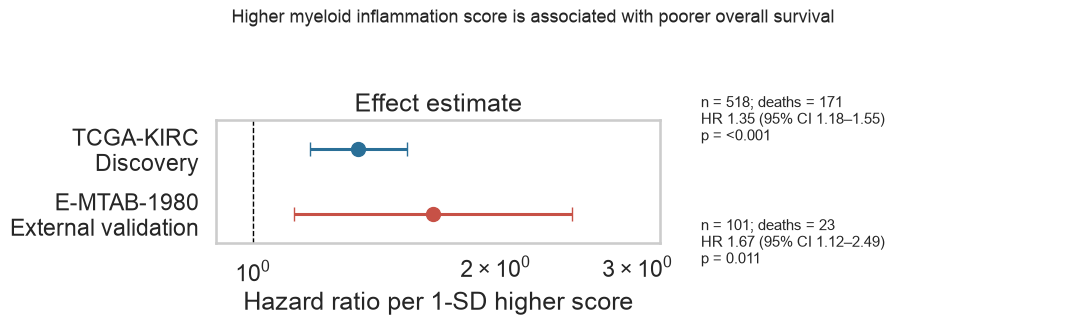

Figure replaced: figure_10_external_myeloid_validation.png


In [38]:
plot_data = validation_comparison.copy()

fig, (axis_forest, axis_details) = plt.subplots(
    ncols=2,
    figsize=(11, 3.2),
    gridspec_kw={"width_ratios": [1.25, 1]},
)

y_positions = [1, 0]
cohort_labels = ["TCGA-KIRC\nDiscovery", "E-MTAB-1980\nExternal validation"]
colors = ["#2A6F97", "#C75146"]

for y_position, (_, row), color in zip(
    y_positions,
    plot_data.iterrows(),
    colors,
):
    axis_forest.errorbar(
    row["hazard_ratio_per_SD"],
    y_position,
    xerr=[
        [row["hazard_ratio_per_SD"] - row["lower_95_CI"]],
        [row["upper_95_CI"] - row["hazard_ratio_per_SD"]],
    ],
    fmt="o",
    color=color,
    markersize=10,
    capsize=5,
    linewidth=2.2,
)

axis_forest.axvline(1, color="black", linestyle="--", linewidth=1)
axis_forest.set_xscale("log")
axis_forest.set_xlim(0.9, 3.2)
axis_forest.set_ylim(-0.45, 1.45)
axis_forest.set_yticks(y_positions)
axis_forest.set_yticklabels(cohort_labels)
axis_forest.set_xlabel("Hazard ratio per 1-SD higher score")
axis_forest.set_title("Effect estimate")
axis_forest.grid(axis="x", alpha=0.25)
axis_forest.grid(axis="y", visible=False)

axis_details.axis("off")
#axis_details.set_title("Results", loc="left")

for y_position, (_, row) in zip(y_positions, plot_data.iterrows()):
    p_value_text = (
        "<0.001" if row["p_value"] < 0.001 else f"{row['p_value']:.3f}"
    )

    result_text = (
        f"n = {int(row['patients'])}; deaths = {int(row['deaths'])}\n"
        f"HR {row['hazard_ratio_per_SD']:.2f} "
        f"(95% CI {row['lower_95_CI']:.2f}–{row['upper_95_CI']:.2f})\n"
        f"p = {p_value_text}"
    )

    axis_details.text(
        0,
        y_position,
        result_text,
        va="center",
        fontsize=11,
    )

fig.suptitle(
    "Higher myeloid inflammation score is associated with poorer overall survival",
    fontsize=13,
    y=1.04,
)

plt.tight_layout()

validation_figure_file = (
    PROJECT_DIR
    / "results"
    / "figures"
    / "figure_10_external_myeloid_validation.png"
)

fig.savefig(validation_figure_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure replaced: {validation_figure_file.name}")

The red interval is longer because the external cohort has fewer patients and far fewer deaths, so its estimate is less precise. Both intervals are entirely to the right of 1, supporting the same adverse-survival association.

Blue = TCGA-KIRC discovery cohort: 518 patients, 171 deaths.
Red = E-MTAB-1980 external-validation cohort: 101 patients, 23 deaths.
The dot is the estimated hazard ratio.

The horizontal line is its 95% confidence interval

### 07-15 Checking the proportional-hazards assumption externally


In [44]:

external_ph_checks = external_cox_model.check_assumptions(
    external_cox_data[
        [
            "overall_survival_months",
            "event_observed",
            "myeloid_score_per_sd",
        ]
    ],
    p_value_threshold=0.05,
    show_plots=False,
)


Proportional hazard assumption looks okay.


### 07-16 Saving external proportional-hazards test results


In [41]:

from lifelines.statistics import proportional_hazard_test

external_ph_test = proportional_hazard_test(
    external_cox_model,
    external_cox_data[
        [
            "overall_survival_months",
            "event_observed",
            "myeloid_score_per_sd",
        ]
    ],
    time_transform=["rank", "km", "identity", "log"],
)

external_ph_results = external_ph_test.summary.reset_index().rename(
    columns={"index": "time_transform"}
)

external_ph_table_file = (
    PROJECT_DIR
    / "results"
    / "tables"
    / "table_10_external_proportional_hazards_checks.csv"
)

external_ph_results.to_csv(external_ph_table_file, index=False)

print(f"PH-check table saved as: {external_ph_table_file.name}")
display(external_ph_results.round(4))

PH-check table saved as: table_10_external_proportional_hazards_checks.csv


,level_0,level_1,test_statistic,p,-log2(p)
0,myeloid_score_per_sd,identity,2.5149,0.1128,3.1485
1,myeloid_score_per_sd,km,1.1186,0.2902,1.7848
2,myeloid_score_per_sd,log,1.2472,0.2641,1.9210
3,myeloid_score_per_sd,rank,1.0734,0.3002,1.7361


All four p-values are above 0.05, so the proportional-hazards is acceptable

###  07-17  Plotting external survival by myeloid inflammation level


Higher-score patients: 45
Lower-score patients: 56
Log-rank p-value: 0.037


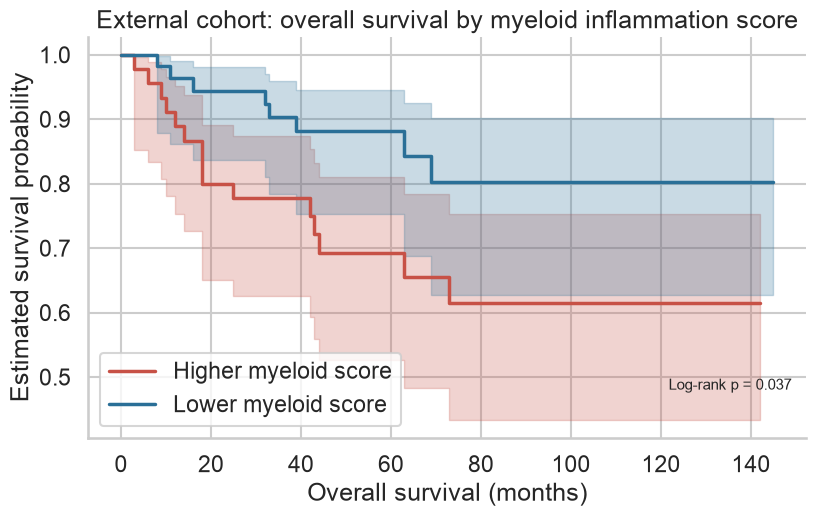

Figure saved as: figure_11_external_myeloid_kaplan_meier.png


In [46]:

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

external_km_data = external_cox_data.copy()

external_km_data["myeloid_group"] = np.where(
    external_km_data["myeloid_score_per_sd"] >= 0,
    "Higher myeloid score",
    "Lower myeloid score",
)

higher_score = external_km_data[
    external_km_data["myeloid_group"] == "Higher myeloid score"
]

lower_score = external_km_data[
    external_km_data["myeloid_group"] == "Lower myeloid score"
]

logrank_result = logrank_test(
    higher_score["overall_survival_months"],
    lower_score["overall_survival_months"],
    event_observed_A=higher_score["event_observed"],
    event_observed_B=lower_score["event_observed"],
)

print("Higher-score patients:", len(higher_score))
print("Lower-score patients:", len(lower_score))
print(f"Log-rank p-value: {logrank_result.p_value:.3f}")

fig, axis = plt.subplots(figsize=(8.5, 5.5))

kmf_higher = KaplanMeierFitter()
kmf_lower = KaplanMeierFitter()

kmf_higher.fit(
    higher_score["overall_survival_months"],
    event_observed=higher_score["event_observed"],
    label="Higher myeloid score",
)
kmf_higher.plot_survival_function(
    ax=axis,
    ci_show=True,
    color="#C75146",
    linewidth=2.5,
)

kmf_lower.fit(
    lower_score["overall_survival_months"],
    event_observed=lower_score["event_observed"],
    label="Lower myeloid score",
)
kmf_lower.plot_survival_function(
    ax=axis,
    ci_show=True,
    color="#2A6F97",
    linewidth=2.5,
)

axis.set_title("External cohort: overall survival by myeloid inflammation score")
axis.set_xlabel("Overall survival (months)")
axis.set_ylabel("Estimated survival probability")
axis.text(
    0.98,
    0.12,
    f"Log-rank p = {logrank_result.p_value:.3f}",
    transform=axis.transAxes,
    ha="right",
    fontsize=11,
)
axis.legend(frameon=True)
sns.despine()
plt.tight_layout()

external_km_figure_file = (
    PROJECT_DIR
    / "results"
    / "figures"
    / "figure_11_external_myeloid_kaplan_meier.png"
)

fig.savefig(external_km_figure_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved as: {external_km_figure_file.name}")

The Kaplan–Meier plot is consistent with the continuous-score Cox result

### 07-18  Saving external-validation model and Kaplan–Meier results


In [ ]:

external_cox_table = external_cox_results.reset_index().rename(
    columns={"covariate": "variable"}
)

external_cox_table["patients"] = len(external_cox_data)
external_cox_table["deaths"] = int(external_cox_data["event_observed"].sum())
external_cox_table["concordance_index"] = external_cox_model.concordance_index_

external_km_summary = (
    external_km_data
    .groupby("myeloid_group")
    .agg(
        patients=("patient_id", "count"),
        deaths=("event_observed", "sum"),
        median_score=("myeloid_score_per_sd", "median"),
    )
    .reset_index()
)

external_km_summary["logrank_p_value"] = logrank_result.p_value

external_cox_table_file = (
    PROJECT_DIR
    / "results"
    / "tables"
    / "table_11_external_myeloid_cox_results.csv"
)

external_km_table_file = (
    PROJECT_DIR
    / "results"
    / "tables"
    / "table_12_external_myeloid_kaplan_meier_summary.csv"
)

external_cox_table.to_csv(external_cox_table_file, index=False)
external_km_summary.to_csv(external_km_table_file, index=False)

print(f"Cox-results table saved as: {external_cox_table_file.name}")
print(f"Kaplan–Meier summary saved as: {external_km_table_file.name}")

display(external_cox_table.round(3))
display(external_km_summary.round(3))

## External-validation conclusion

In the independent E-MTAB-1980 cohort (101 patients; 23 deaths), a one-standard-deviation higher myeloid inflammation score was associated with poorer overall survival (HR 1.67, 95% CI 1.12–2.49; p = 0.011). The direction of association agrees with TCGA-KIRC (HR 1.35, 95% CI 1.18–1.55).

The external proportional-hazards checks did not indicate an important violation. Kaplan–Meier curves using the pre-defined score-zero split were also separated (log-rank p = 0.037). Because this cohort has only 23 deaths and uses a different expression platform, this supports external replication of the association, not clinical causality.

Two useful robustness checks remain:
1. Does the result persist if any one myeloid gene is removed?
2. Is the result still positive for every four-gene version of the score?

### 07-19  Checking whether one gene alone drives the external association


In [56]:

leave_one_out_results = []

for omitted_gene in myeloid_genes:
    retained_genes = [
        gene_name
        for gene_name in myeloid_genes
        if gene_name != omitted_gene
    ]

    temporary_score = external_myeloid_zscore.loc[retained_genes].mean(axis=0)
    temporary_score = (
        temporary_score - temporary_score.mean()
    ) / temporary_score.std(ddof=0)

    temporary_model_data = external_cox_data[
        [
            "patient_id",
            "overall_survival_months",
            "event_observed",
        ]
    ].copy()

    temporary_model_data["score_per_sd"] = temporary_model_data[
        "patient_id"
    ].map(temporary_score)

    assert temporary_model_data["score_per_sd"].notna().all()

    temporary_model = CoxPHFitter()
    temporary_model.fit(
        temporary_model_data[
            [
                "overall_survival_months",
                "event_observed",
                "score_per_sd",
            ]
        ],
        duration_col="overall_survival_months",
        event_col="event_observed",
    )

    leave_one_out_results.append(
        {
            "omitted_gene": omitted_gene,
            "genes_in_score": ", ".join(retained_genes),
            "hazard_ratio_per_SD": temporary_model.hazard_ratios_["score_per_sd"],
            "lower_95_CI": np.exp(
                temporary_model.confidence_intervals_.loc[
                    "score_per_sd", "95% lower-bound"
                ]
            ),
            "upper_95_CI": np.exp(
                temporary_model.confidence_intervals_.loc[
                    "score_per_sd", "95% upper-bound"
                ]
            ),
            "p_value": temporary_model.summary.loc["score_per_sd", "p"],
        }
    )

leave_one_out_results = pd.DataFrame(leave_one_out_results)

leave_one_out_file = (
    PROJECT_DIR
    / "results"
    / "tables"
    / "table_13_external_myeloid_leave_one_gene_out.csv"
)

leave_one_out_results.to_csv(leave_one_out_file, index=False)

print(f"Leave-one-gene-out results saved as: {leave_one_out_file.name}")
display(leave_one_out_results.round(3))

Leave-one-gene-out results saved as: table_13_external_myeloid_leave_one_gene_out.csv


,omitted_gene,genes_in_score,hazard_ratio_per_SD,lower_95_CI,upper_95_CI,p_value
0,CXCL1,"CXCL2, CXCL3, IL6, PTGS2",1.627,1.115,2.375,0.012
1,CXCL2,"CXCL1, CXCL3, IL6, PTGS2",1.637,1.118,2.396,0.011
2,CXCL3,"CXCL1, CXCL2, IL6, PTGS2",1.698,1.135,2.541,0.010
3,IL6,"CXCL1, CXCL2, CXCL3, PTGS2",1.617,1.078,2.425,0.020
4,PTGS2,"CXCL1, CXCL2, CXCL3, IL6",1.702,1.125,2.575,0.012


A leave-one-gene-out sensitivity analysis produced consistent results: 
after removing each of CXCL1, CXCL2, CXCL3, IL6, or PTGS2 in turn, 
the four-gene score remained associated with poorer survival 
(HR range 1.62–1.70; all p ≤ 0.020). 
This indicates that the association was not driven by a single gene.

That completes the meaningful verification for Stage 07:
- independent cohort replication;
- continuous Cox model;
- proportional-hazards checks;
- descriptive Kaplan–Meier confirmation;
- leave-one-gene-out robustness.

### # 07-20 Checking survival associations for individual myeloid genes


In [53]:

from statsmodels.stats.multitest import multipletests

external_gene_scores = (
    external_myeloid_zscore
    .loc[myeloid_genes]
    .T
    .rename_axis("patient_id")
    .reset_index()
)

external_gene_cox_data = external_cox_data[
    [
        "patient_id",
        "overall_survival_months",
        "event_observed",
    ]
].merge(
    external_gene_scores,
    on="patient_id",
    how="inner",
    validate="one_to_one",
)

individual_gene_results = []

for gene_name in myeloid_genes:
    gene_model = CoxPHFitter()

    gene_model.fit(
        external_gene_cox_data[
            [
                "overall_survival_months",
                "event_observed",
                gene_name,
            ]
        ],
        duration_col="overall_survival_months",
        event_col="event_observed",
    )

    individual_gene_results.append(
        {
            "gene_name": gene_name,
            "hazard_ratio_per_SD": gene_model.hazard_ratios_[gene_name],
            "lower_95_CI": np.exp(
                gene_model.confidence_intervals_.loc[
                    gene_name, "95% lower-bound"
                ]
            ),
            "upper_95_CI": np.exp(
                gene_model.confidence_intervals_.loc[
                    gene_name, "95% upper-bound"
                ]
            ),
            "p_value": gene_model.summary.loc[gene_name, "p"],
        }
    )

individual_gene_results = pd.DataFrame(individual_gene_results)

individual_gene_results["fdr_q_value"] = multipletests(
    individual_gene_results["p_value"],
    method="fdr_bh",
)[1]

individual_gene_results["higher_expression_associated_with_poorer_survival"] = (
    individual_gene_results["hazard_ratio_per_SD"] > 1
)

individual_gene_results = individual_gene_results.sort_values(
    "p_value"
).reset_index(drop=True)

individual_gene_file = (
    PROJECT_DIR
    / "results"
    / "tables"
    / "table_14_external_individual_myeloid_gene_results.csv"
)

individual_gene_results.to_csv(individual_gene_file, index=False)

print(f"Individual-gene results saved as: {individual_gene_file.name}")
display(individual_gene_results.round(3))

Individual-gene results saved as: table_14_external_individual_myeloid_gene_results.csv


,gene_name,hazard_ratio_per_SD,lower_95_CI,upper_95_CI,p_value,fdr_q_value,higher_expression_associated_with_poorer_survival
0,IL6,1.627,1.119,2.365,0.011,0.054,True
1,CXCL2,1.601,1.046,2.450,0.030,0.062,True
2,CXCL1,1.575,1.000,2.481,0.050,0.062,True
3,CXCL3,1.474,0.997,2.180,0.052,0.062,True
4,PTGS2,1.426,0.982,2.071,0.062,0.062,True


IL6 has the strongest external single-gene association: HR 1.63, p = 0.011.
But after correcting five gene tests, IL6 q = 0.054, just above 0.05.
Therefore: IL6 is a promising candidate, not proven to be the driver.
The leave-one-out analysis shows the score remains strong without IL6, 
so the signal is shared across the five-gene inflammatory pattern.

#  summary External validation in E-MTAB-1980
This notebook tested whether the adverse overall-survival association of the 
TCGA-KIRC myeloid inflammation signature could be replicated in an independent 
clear-cell renal cell carcinoma cohort.

## External dataset and harmonization

The E-MTAB-1980 cohort contains expression data from 101 ccRCC tumour samples 
measured using an Agilent microarray platform. All 101 expression samples matched
the sample metadata and the survival data extracted from Supplementary Table 1 
of Sato et al. Clinical follow-up included 23 deaths and 78 censored patients, 
with observed survival times from 1 to 145 months.

The external expression platform differs from TCGA RNA sequencing. 
Therefore, direct expression values were not compared across cohorts. 
Instead, each of the five myeloid genes was standardized within E-MTAB-1980, 
and the external myeloid inflammation score was calculated as the mean of 
these standardized values.

All five myeloid genes were available in the processed external expression matrix:

- CXCL1
- CXCL2
- CXCL3
- IL6
- PTGS2

## Primary external validation result

A Cox proportional-hazards model tested the continuous external myeloid score, 
per one-standard-deviation increase.

| Cohort                        | Patients | Deaths | Hazard ratio per SD | 95% CI    | p-value |

| TCGA-KIRC discovery cohort    | 518      | 171    | 1.35                | 1.18–1.55 | <0.001 |

| E-MTAB-1980 external cohort   | 101      | 23     | 1.67                | 1.12–2.49 | 0.011 |

Higher myeloid inflammation was associated with poorer overall survival in both cohorts. 
The external result had a wider confidence interval because the cohort had fewer patients 
and substantially fewer deaths.

The TCGA discovery model was adjusted for clinical covariates and stratified by pathological stage.
The external model was intentionally unadjusted because only 23 deaths were available; 
a large multivariable model would be unstable.

## Model checks and descriptive survival plot

External proportional-hazards tests found no evidence that the myeloid-score 
effect changed substantially over time:

- Identity transform: p = 0.113
- Kaplan–Meier transform: p = 0.290
- Log transform: p = 0.264
- Rank transform: p = 0.300

For descriptive visualization, patients were grouped using the pre-defined 
score-zero threshold: above versus below the external cohort mean. 

Higher-score patients had poorer Kaplan–Meier survival than lower-score 
patients(log-rank p = 0.037). This grouped plot supports the continuous
Cox-model finding but is not the primary analysis.

## Robustness to individual genes

Leave-one-gene-out analyses removed one gene at a time and recalculated 
the four-gene score. Every reduced score remained associated with poorer survival:

- HR range: 1.62–1.70
- p-value range: 0.010–0.020

Therefore, the external association was not dependent on one individual gene.

Individual-gene exploratory models suggested that IL6 had the strongest 
single-gene association with poorer survival (HR 1.63, p = 0.011). 
However, its false-discovery-rate adjusted q-value was 0.054, and 
the leave-one-gene-out result showed that removing IL6 did not eliminate 
the signature association. 

## Interpretation and limitations

This stage provides independent external replication of the association
between higher myeloid inflammation and poorer overall survival in ccRCC. 
It does not establish causality

Important limitations are the small number of external deaths, 
the different expression platforms, 
within-cohort score standardization, 
and the intentionally frugal external Cox model.

## Data sources

- Sato Y, et al. *Integrated molecular analysis of clear-cell renal cell carcinoma.* Nature Genetics. 2013;45:860–867. https://doi.org/10.1038/ng.2699
- External gene-expression dataset: E-MTAB-1980, publicly archived by EMBL-EBI ArrayExpress/BioStudies.